In [1]:
from datasets import load_dataset

dataset = load_dataset(
    "abisee/cnn_dailymail",
    "3.0.0"
)

train_data = dataset["train"]
val_data = dataset["validation"]
test_data = dataset["test"]
print(dataset)

README.md:   0%|          | 0.00/15.6k [00:00<?, ?B/s]

3.0.0/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  257MB            

3.0.0/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

3.0.0/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  259MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/287113 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/13368 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/11490 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 287113
    })
    validation: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 13368
    })
    test: Dataset({
        features: ['article', 'highlights', 'id'],
        num_rows: 11490
    })
})


In [2]:

print("\nTraining examples:", len(train_data))
print("Validation examples:", len(val_data))
print("Testing examples:", len(test_data))


Training examples: 287113
Validation examples: 13368
Testing examples: 11490


In [4]:
sample = train_data[0]

print(sample.keys())

dict_keys(['article', 'highlights', 'id'])


In [3]:
sample = train_data[0]

print("=" * 60)
print("ARTICLE")
print("=" * 60)
print(sample["article"])

print("\n" + "=" * 60)
print("SUMMARY")
print("=" * 60)
print(sample["highlights"])

print("\nARTICLE CHARACTERS:", len(sample["article"]))
print("SUMMARY CHARACTERS:", len(sample["highlights"]))

ARTICLE
LONDON, England (Reuters) -- Harry Potter star Daniel Radcliffe gains access to a reported £20 million ($41.1 million) fortune as he turns 18 on Monday, but he insists the money won't cast a spell on him. Daniel Radcliffe as Harry Potter in "Harry Potter and the Order of the Phoenix" To the disappointment of gossip columnists around the world, the young actor says he has no plans to fritter his cash away on fast cars, drink and celebrity parties. "I don't plan to be one of those people who, as soon as they turn 18, suddenly buy themselves a massive sports car collection or something similar," he told an Australian interviewer earlier this month. "I don't think I'll be particularly extravagant. "The things I like buying are things that cost about 10 pounds -- books and CDs and DVDs." At 18, Radcliffe will be able to gamble in a casino, buy a drink in a pub or see the horror film "Hostel: Part II," currently six places below his number one movie on the UK box office chart. Detail

In [5]:
def check_empty(dataset):

    empty_articles = 0
    empty_summaries = 0

    for example in dataset:

        if not example["article"].strip():
            empty_articles += 1

        if not example["highlights"].strip():
            empty_summaries += 1

    return empty_articles, empty_summaries


empty_articles, empty_summaries = check_empty(train_data)

print("Empty articles:", empty_articles)
print("Empty summaries:", empty_summaries)

Empty articles: 0
Empty summaries: 0


In [6]:
import numpy as np

article_lengths = [
    len(example["article"].split())
    for example in train_data
]

summary_lengths = [
    len(example["highlights"].split())
    for example in train_data
]


def print_statistics(lengths, name):

    print(f"\n{name} Length Statistics")
    print("-" * 40)

    print("Mean:", round(np.mean(lengths), 2))
    print("Median:", np.median(lengths))
    print("Minimum:", np.min(lengths))
    print("Maximum:", np.max(lengths))

    print("90th percentile:", np.percentile(lengths, 90))
    print("95th percentile:", np.percentile(lengths, 95))
    print("99th percentile:", np.percentile(lengths, 99))


print_statistics(article_lengths, "Article")
print_statistics(summary_lengths, "Summary")


Article Length Statistics
----------------------------------------
Mean: 691.87
Median: 632.0
Minimum: 8
Maximum: 2347
90th percentile: 1166.0
95th percentile: 1363.0
99th percentile: 1674.0

Summary Length Statistics
----------------------------------------
Mean: 51.57
Median: 48.0
Minimum: 4
Maximum: 1296
90th percentile: 77.0
95th percentile: 90.0
99th percentile: 120.0


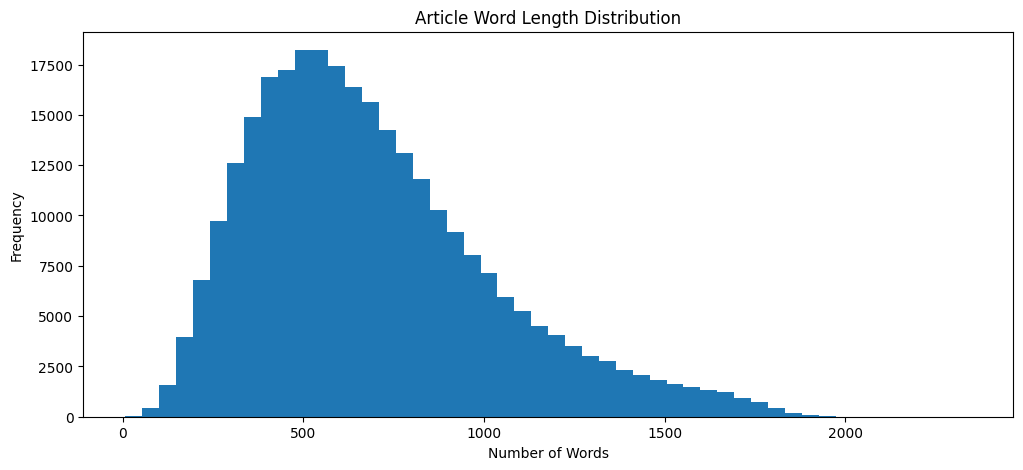

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.hist(article_lengths, bins=50)

plt.title("Article Word Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

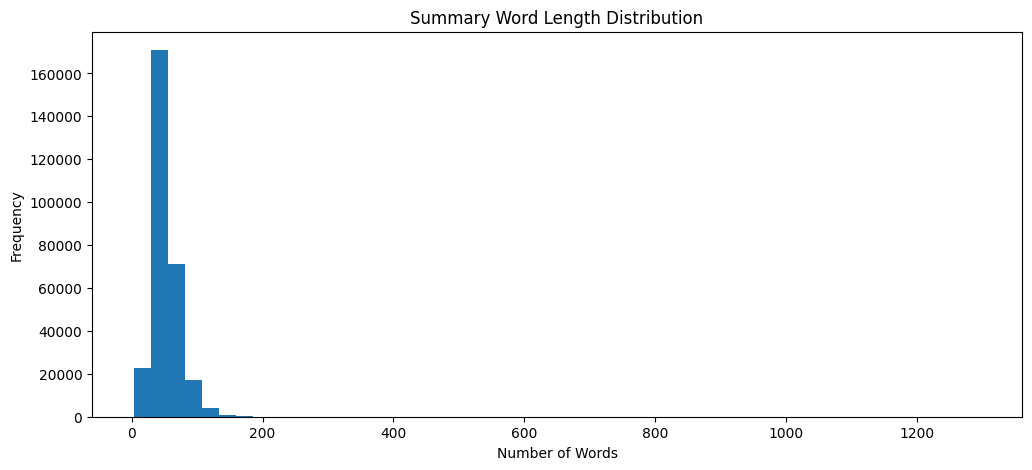

In [8]:
plt.figure(figsize=(12, 5))

plt.hist(summary_lengths, bins=50)

plt.title("Summary Word Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [9]:
longest_summary_indices = sorted(
    range(len(summary_lengths)),
    key=lambda i: summary_lengths[i],
    reverse=True
)[:5]

for i in longest_summary_indices:

    print("=" * 70)
    print("Summary words:", summary_lengths[i])
    print("Article words:", article_lengths[i])
    print("\nSUMMARY:\n")
    print(train_data[i]["highlights"][:1500])

Summary words: 1296
Article words: 550

SUMMARY:

The Great British Bake Off final expects to draw an audience of over 4 million tonight .
27% of Britons say they will bake more in the next year .
National Baking Week runs 15th -21st October .
Baking is most popular in Yorkshire .
1 in 7 adults bake at least twice a week .
Servants leave for the First World War and work in other careers. Women work in armament factories and in other jobs, giving them less time to bake .
The Women’s Institute is founded in 1915. Advice on cookery is offered and members share their experiences at meetings. After the war their magazine Home and Country, offers recipes and advice .
The National Confectionary Industry started to issue adverts in press, encouraging women to take up home baking as a source of extra income .
Good Housekeeping Magazine is first published in 1922 .
Ready shredded packets of beef suet are advertised with the strapline of “What visions of delight...”. The advert refers to Spotted 

In [10]:

article_lengths = np.array(article_lengths)
summary_lengths = np.array(summary_lengths)

# Summary longer than article
longer_summaries = summary_lengths > article_lengths

# Summary longer than 200 words
extreme_summaries = summary_lengths > 200

# Very short articles
short_articles = article_lengths < 50

print("Total training examples:", len(train_data))

print(
    "Summaries longer than articles:",
    np.sum(longer_summaries)
)

print(
    "Summaries longer than 200 words:",
    np.sum(extreme_summaries)
)

print(
    "Articles shorter than 50 words:",
    np.sum(short_articles)
)

print(
    "Percentage of summaries longer than articles:",
    round(np.mean(longer_summaries) * 100, 2), "%"
)

Total training examples: 287113
Summaries longer than articles: 26
Summaries longer than 200 words: 174
Articles shorter than 50 words: 29
Percentage of summaries longer than articles: 0.01 %


In [11]:
ratios = summary_lengths / np.maximum(article_lengths, 1)

print("Mean ratio:", np.mean(ratios))
print("Median ratio:", np.median(ratios))
print("95th percentile:", np.percentile(ratios, 95))
print("99th percentile:", np.percentile(ratios, 99))

Mean ratio: 0.09087536118318482
Median ratio: 0.07834101382488479
95th percentile: 0.18867924528301888
99th percentile: 0.269294509633493


In [12]:
long_summary_indices = [
    i for i, length in enumerate(summary_lengths)
    if length > 200
]

print("Number of long summaries:", len(long_summary_indices))

for i in long_summary_indices[:10]:

    print("\n" + "=" * 70)
    print("INDEX:", i)
    print("ARTICLE WORDS:", article_lengths[i])
    print("SUMMARY WORDS:", summary_lengths[i])

    print("\nSUMMARY:")
    print(train_data[i]["highlights"][:1000])

Number of long summaries: 174

INDEX: 96257
ARTICLE WORDS: 1271
SUMMARY WORDS: 225

SUMMARY:
Counter Terrorism Command (SO15) officers examined all of Gareth Williams's IT equipment BEFORE handing it over to murder squad detectives .
Coroner Fiona Wilcox calls on SO15 to provide a witness to the inquest to explain their role in the investigations into Mr Williams's death .
Mr Williams's family believe a third party was either present when he died or broke into his home afterwards to destroy evidence .
DNA found on the dead spy's hand which police believed was significant actually belonged to a bungling forensic scientist .
Relatives want to know why MI6 did not raise the alarm when Mr Williams  failed to turn up at work - by then his body was badly decomposed .
Mr Williams had said was worried .
that he was being followed in the days before his death, but MI6 failed .
to pass this on to murder detectives; .
An expert seeking signs of forced .
entry said he was hampered because the fron

In [13]:
!pip install sentencepiece

In [14]:
import sentencepiece as spm
import os

In [15]:
corpus_path = "/content/training_corpus.txt"

with open(corpus_path, "w", encoding="utf-8") as f:

    for example in train_data:

        article = example["article"].replace("\n", " ").strip()
        summary = example["highlights"].replace("\n", " ").strip()

        f.write(article + "\n")
        f.write(summary + "\n")

print("Corpus created successfully!")
print("File size:", round(os.path.getsize(corpus_path) / (1024**2), 2), "MB")

Corpus created successfully!
File size: 1189.56 MB


In [16]:
spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix="/content/gpt_tokenizer",
    vocab_size=10000,
    model_type="bpe",
    character_coverage=0.9995,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3
)

True

In [17]:
tokenizer = spm.SentencePieceProcessor()

tokenizer.load("/content/gpt_tokenizer.model")

print("Vocabulary size:", tokenizer.get_piece_size())

Vocabulary size: 10000


In [18]:
sample_text = "The cat is sleeping on the sofa."

tokens = tokenizer.encode(
    sample_text,
    out_type=str
)

token_ids = tokenizer.encode(
    sample_text,
    out_type=int
)

print("Original text:", sample_text)
print("Tokens:", tokens)
print("Token IDs:", token_ids)
print("Number of tokens:", len(token_ids))

Original text: The cat is sleeping on the sofa.
Tokens: ['▁The', '▁cat', '▁is', '▁sleeping', '▁on', '▁the', '▁so', 'f', 'a', '.']
Token IDs: [89, 2779, 86, 7013, 63, 10, 380, 9938, 9925, 9944]
Number of tokens: 10


In [21]:
article_token_lengths = []
summary_token_lengths = []

for example in train_data:

    article_ids = tokenizer.encode(example["article"])
    summary_ids = tokenizer.encode(example["highlights"])

    article_token_lengths.append(len(article_ids))
    summary_token_lengths.append(len(summary_ids))

KeyboardInterrupt: 

In [22]:

def token_statistics(lengths, name):

    print(f"\n{name} Token Statistics")
    print("-" * 40)

    print("Mean:", round(np.mean(lengths), 2))
    print("Median:", np.median(lengths))
    print("Minimum:", np.min(lengths))
    print("Maximum:", np.max(lengths))

    print("90th percentile:", np.percentile(lengths, 90))
    print("95th percentile:", np.percentile(lengths, 95))
    print("99th percentile:", np.percentile(lengths, 99))


token_statistics(article_token_lengths, "Article")
token_statistics(summary_token_lengths, "Summary")


Article Token Statistics
----------------------------------------
Mean: 864.93
Median: 809.0
Minimum: 100
Maximum: 2790
90th percentile: 1442.1999999999998
95th percentile: 1617.8000000000002
99th percentile: 2068.759999999999

Summary Token Statistics
----------------------------------------
Mean: 61.27
Median: 62.0
Minimum: 31
Maximum: 102
90th percentile: 76.0
95th percentile: 80.0
99th percentile: 86.0


In [23]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
import os

PROJECT_DIR = "/content/drive/MyDrive/GPT_Text_Summarization"

TOKENIZER_DIR = os.path.join(PROJECT_DIR, "tokenizer")

os.makedirs(TOKENIZER_DIR, exist_ok=True)

print("Directory created:", TOKENIZER_DIR)

Directory created: /content/drive/MyDrive/GPT_Text_Summarization/tokenizer


In [25]:
import shutil

shutil.copy(
    "/content/gpt_tokenizer.model",
    TOKENIZER_DIR
)

shutil.copy(
    "/content/gpt_tokenizer.vocab",
    TOKENIZER_DIR
)

print("Tokenizer saved successfully!")

Tokenizer saved successfully!
